# Risk Alert Classifier

In [1]:
import warnings, os, json, time
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score, roc_auc_score, roc_curve,
                             classification_report, precision_recall_curve)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
os.makedirs('images', exist_ok=True)
os.makedirs('model', exist_ok=True)

def save_fig(name):
    plt.savefig(f'images/{name}.png', dpi=130, bbox_inches='tight')

---
# Part A: Conceptual Understanding (Theory)

**1. What is Logistic Regression and why is it suitable for classification?**
Logistic Regression is a supervised model that first computes a linear score
`z = b0 + b1·x1 + ... + bn·xn` and then passes it through the sigmoid function `σ(z) = 1 / (1 + e^(−z))`
to get a **probability between 0 and 1**. If the probability is above a threshold (default 0.5) the customer is
classified as class 1 (high risk). It is suitable for classification because the output is a probability,
it is fast, works well as a baseline and its coefficients are easy to interpret (they show how each feature pushes the odds of risk up or down).

**2. Classification performance metrics and why accuracy alone is insufficient.**
All metrics come from the confusion matrix (TP, TN, FP, FN): Accuracy, Precision, Recall, F1-Score, ROC-AUC etc.
Accuracy = (TP + TN) / total, so on imbalanced data it is misleading. Example: if only 12% of customers are high-risk,
a model that predicts "low risk" for everybody gets about 88% accuracy but catches **zero** risky customers.
Hence we also need Recall, Precision, F1 and AUC.

**3. Type-I and Type-II error in risk prediction.**
*Type-I error (False Positive):* a genuinely low-risk customer is flagged as high-risk the bank loses goodwill and wastes review effort.
*Type-II error (False Negative):* a genuinely high-risk customer is predicted as low-risk the default/fraud goes undetected and
the bank loses money. For an early-warning system Type-II is normally more costly.

**4. Precision, Recall, F1-Score, TPR and FPR.**
- **Precision** = TP / (TP + FP) → of all customers flagged high-risk, how many really are.
- **Recall = TPR (Sensitivity)** = TP / (TP + FN) → of all truly high-risk customers, how many we caught.
- **F1-Score** = 2·Precision·Recall / (Precision + Recall) → harmonic mean, balances both.
- **FPR** = FP / (FP + TN) → share of low-risk customers wrongly flagged.

**5. What is AUC-ROC and how does it help?**
The ROC curve plots TPR (y-axis) against FPR (x-axis) for **every possible threshold**. AUC is the area under that curve:
0.5 = random guessing, 1.0 = perfect separation. It measures how well the model *ranks* risky customers above safe ones,
independent of any single threshold, so it is useful for comparing models.

**6. Why does imbalanced data create problems?**
The model sees very few minority (high-risk) examples, and because it minimises overall error it learns to favour the
majority class. Result: high accuracy but low recall for the minority class, a decision boundary pushed towards the minority,
and misleading metrics. We fix it with resampling (under/over-sampling, SMOTE, ADASYN), class weights, threshold tuning and better metrics.

# Part B: Dataset Understanding & Preparation
## Q7. Identify input features and target variable

In [2]:
df = pd.read_csv('Risk_Alert_Classifier_Dataset_4600.csv')
print('Shape:', df.shape)
display(df.head())
df.info()

Shape: (4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

### Feature engineering

In [3]:
df['last_transaction_date'] = pd.to_datetime(df['last_transaction_date'])
REF_DATE = df['last_transaction_date'].max() + pd.Timedelta(days=1)
df['days_since_last_txn'] = (REF_DATE - df['last_transaction_date']).dt.days

target = 'risk_status'
drop_cols = ['customer_id', 'last_transaction_date', target]
X = df.drop(columns=drop_cols)
y = df[target]

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

print('Target variable :', target, '(0 = Low Risk, 1 = High Risk)')
print('Numeric features (%d):' % len(num_cols), num_cols)
print('Categorical features (%d):' % len(cat_cols), cat_cols)

Target variable : risk_status (0 = Low Risk, 1 = High Risk)
Numeric features (14): ['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr', 'days_since_last_txn']
Categorical features (3): ['gender', 'region', 'employment_type']


,Feature group,Columns
0,Customer demographics,"age, gender, region, employment_type, annual_i..."
1,Credit behaviour,"credit_score, credit_utilization_ratio, missed..."
2,Transaction / account activity,"monthly_transaction_count, monthly_spend_inr, ..."


risk_status
Low Risk (0)     4043
High Risk (1)     557
Name: count, dtype: int64 
High-risk share: 12.11%


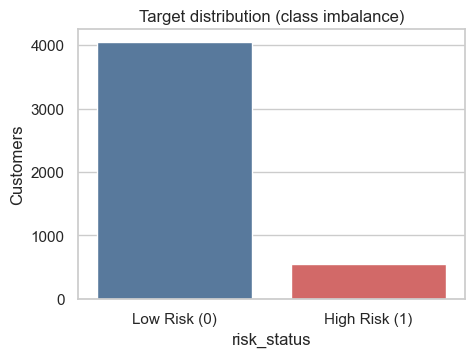

In [4]:
groups = {
    'Customer demographics': ['age', 'gender', 'region', 'employment_type', 'annual_income_inr'],
    'Credit behaviour': ['credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days',
                         'cash_advance_count_6m', 'debt_balance_inr'],
    'Transaction / account activity': ['monthly_transaction_count', 'monthly_spend_inr', 'days_since_last_txn',
                                       'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months'],
}
display(pd.DataFrame([(g, ', '.join(c)) for g, c in groups.items()], columns=['Feature group', 'Columns']))

counts = y.value_counts().rename({0: 'Low Risk (0)', 1: 'High Risk (1)'})
print(counts, '\nHigh-risk share: %.2f%%' % (100 * y.mean()))
plt.figure(figsize=(5, 3.5))
sns.barplot(x=counts.index, y=counts.values, palette=['#4C78A8', '#E45756'])
plt.title('Target distribution (class imbalance)'); plt.ylabel('Customers')
save_fig('01_target_distribution'); plt.show()

**Interpretation:** The dataset has 4,600 customers and 17 usable input features (14 numeric + 3 categorical: `gender`, `region`, `employment_type`). The target is `risk_status`. Only **12.1%** of customers are High Risk (557 vs 4,043), so the data is clearly imbalanced. `customer_id` is dropped (just an ID) and the date is converted to `days_since_last_txn`.

## Q8. Train test split while maintaining class distribution (stratified)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

dist = pd.DataFrame({
    'Full data': y.value_counts(normalize=True),
    'Train': y_train.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)}).round(4)
dist.index = ['Low Risk (0)', 'High Risk (1)']
print('Train size:', X_train.shape, ' Test size:', X_test.shape)
display(dist)

Train size: (3680, 17)  Test size: (920, 17)


,Full data,Train,Test
Low Risk (0),0.8789,0.8788,0.8793
High Risk (1),0.1211,0.1212,0.1207


**Interpretation:** `stratify=y` keeps the High-Risk share at about 12.1% in the full data, the train set (3,680 rows) and the test set (920 rows). Without stratification the small minority class could end up under-represented in the test set and make the metrics unreliable.

## Q9. Identify missing values and apply KNN Imputer
Steps (to avoid **data leakage**, everything is *fitted on the training set only*):
1. Numeric columns `StandardScaler` (KNN uses distances, so features must be on one scale) `KNNImputer(n_neighbors=5)`.
2. Categorical columns (`region`, `employment_type`) missing replaced by a separate `"Unknown"` category One-Hot Encoding.

,missing_count,missing_%
credit_score,216,4.70
annual_income_inr,166,3.61
credit_utilization_ratio,147,3.20
employment_type,144,3.13
age,140,3.04
monthly_spend_inr,129,2.80
region,102,2.22


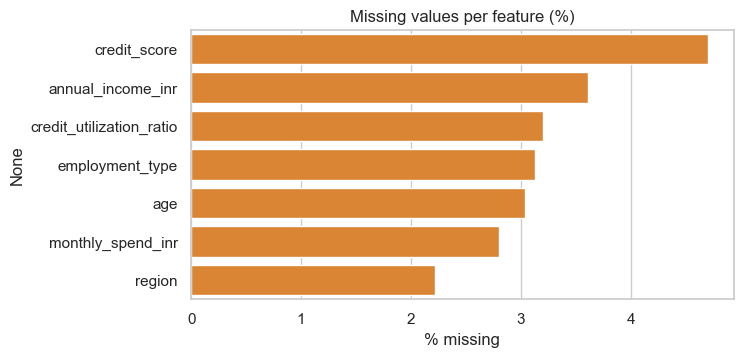

In [6]:
miss = pd.DataFrame({'missing_count': X.isna().sum(), 'missing_%': (100 * X.isna().mean()).round(2)})
miss = miss[miss.missing_count > 0].sort_values('missing_count', ascending=False)
display(miss)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=miss['missing_%'], y=miss.index, color='#F58518')
plt.title('Missing values per feature (%)'); plt.xlabel('% missing')
save_fig('02_missing_values'); plt.show()

In [7]:
num_pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn_imputer', KNNImputer(n_neighbors=5))])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer([('num', num_pipe, num_cols),
                                  ('cat', cat_pipe, cat_cols)])

Xtr_arr = preprocessor.fit_transform(X_train)
Xte_arr = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
feature_names = [f.split('__')[1] for f in feature_names]

X_train_p = pd.DataFrame(Xtr_arr, columns=feature_names, index=X_train.index)
X_test_p = pd.DataFrame(Xte_arr, columns=feature_names, index=X_test.index)

print('Missing values BEFORE (train):', int(X_train.isna().sum().sum()))
print('Missing values AFTER  (train):', int(X_train_p.isna().sum().sum()), '| (test):', int(X_test_p.isna().sum().sum()))
print('Processed train shape:', X_train_p.shape)

Missing values BEFORE (train): 850
Missing values AFTER  (train): 0 | (test): 0
Processed train shape: (3680, 29)


### What did KNN imputer fill in for credit_score? convert back to original units

In [8]:
scaler = preprocessor.named_transformers_['num'].named_steps['scaler']
imputed_num = pd.DataFrame(scaler.inverse_transform(Xtr_arr[:, :len(num_cols)]), columns=num_cols, index=X_train.index)
rows = X_train[X_train['credit_score'].isna()].index[:5]
demo = pd.DataFrame({'credit_score_before': X_train.loc[rows, 'credit_score'],
                     'credit_score_after_KNN': imputed_num.loc[rows, 'credit_score'].round(0)})
display(demo)

,credit_score_before,credit_score_after_KNN
2322,NaN,724.0
1833,NaN,717.0
1728,NaN,679.0
1104,NaN,613.0
26,NaN,707.0


**Interpretation:** 7 columns have missing values (2–5% each; 850 missing cells in the training set). The KNN Imputer fills each numeric gap using the 5 most similar customers (e.g. the missing `credit_score` values were filled with realistic scores between 613 and 724), which is better than a plain mean because it uses the other features. The imputer and scaler were fitted on the train set only, so there is no data leakage. After the pipeline there are **0 missing values** and 29 model-ready columns (14 numeric + one-hot categories).

### Evaluation function
One function evaluates every model in the same way (on the untouched **test set**) and stores the results for the final comparison.

In [9]:
results = []
models = {}

def evaluate(name, model, group, Xtr=None, ytr=None, Xte=None, yte=None):
    Xtr = X_train_p if Xtr is None else Xtr
    ytr = y_train if ytr is None else ytr
    Xte = X_test_p if Xte is None else Xte
    yte = y_test if yte is None else yte
    pred_tr, pred = model.predict(Xtr), model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    row = {'Model': name, 'Group': group,
           'Train Acc': accuracy_score(ytr, pred_tr), 'Test Acc': accuracy_score(yte, pred),
           'Precision': precision_score(yte, pred, zero_division=0), 'Recall': recall_score(yte, pred),
           'F1': f1_score(yte, pred), 'F2': fbeta_score(yte, pred, beta=2), 'AUC': roc_auc_score(yte, proba),
           'TN': tn, 'FP (Type-I)': fp, 'FN (Type-II)': fn, 'TP': tp}
    results.append(row)
    models[name] = model
    return row

def table(names):
    cols = ['Model', 'Train Acc', 'Test Acc', 'Precision', 'Recall', 'F1', 'AUC', 'FP (Type-I)', 'FN (Type-II)']
    df_ = pd.DataFrame(results)
    return df_[df_.Model.isin(names)][cols].set_index('Model').round(4)

# Part C: Baseline Classification Model
## Q10. Implement Logistic Regression as the baseline

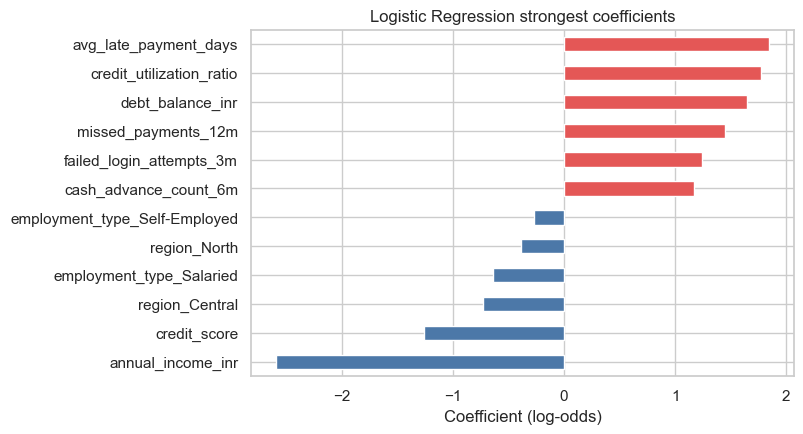

In [10]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_p, y_train)
evaluate('LogReg (baseline)', log_reg, 'Baseline')

coef = pd.Series(log_reg.coef_[0], index=feature_names).sort_values()
top = pd.concat([coef.head(6), coef.tail(6)])
plt.figure(figsize=(7, 4.5))
top.plot(kind='barh', color=['#4C78A8' if v < 0 else '#E45756' for v in top])
plt.title('Logistic Regression strongest coefficients'); plt.xlabel('Coefficient (log-odds)')
save_fig('03_logreg_coefficients'); plt.show()

**Interpretation:** The baseline Logistic Regression was trained on the processed training data. The largest positive coefficients (risk goes up) are `avg_late_payment_days`, `credit_utilization_ratio`, `debt_balance_inr`, `missed_payments_12m` and `failed_login_attempts_3m`; the strongest negative ones (risk goes down) are `annual_income_inr` and `credit_score`. This matches real-world banking logic.

## Q11. Confusion Matrix, Accuracy, Precision, Recall and F1-Score

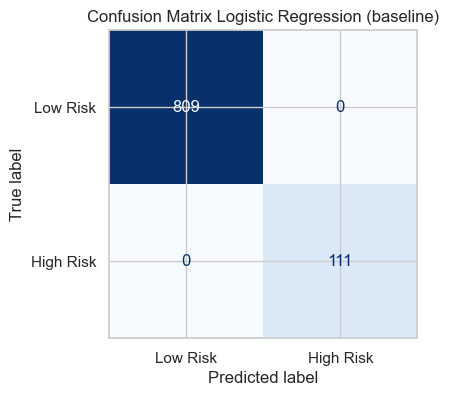

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

               precision    recall  f1-score   support

 Low Risk (0)       1.00      1.00      1.00       809
High Risk (1)       1.00      1.00      1.00       111

     accuracy                           1.00       920
    macro avg       1.00      1.00      1.00       920
 weighted avg       1.00      1.00      1.00       920



In [11]:
y_pred_lr = log_reg.predict(X_test_p)
cm = confusion_matrix(y_test, y_pred_lr)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Low Risk', 'High Risk']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix Logistic Regression (baseline)')
save_fig('04_cm_baseline'); plt.show()

print('Accuracy :', round(accuracy_score(y_test, y_pred_lr), 4))
print('Precision:', round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print('Recall   :', round(recall_score(y_test, y_pred_lr), 4))
print('F1-Score :', round(f1_score(y_test, y_pred_lr), 4))
print()
print(classification_report(y_test, y_pred_lr, target_names=['Low Risk (0)', 'High Risk (1)'], zero_division=0))

**Interpretation:** On the test set the baseline gets Accuracy = Precision = Recall = F1 = **1.00**: all 809 low-risk and all 111 high-risk customers were classified correctly. (Train accuracy is 0.997, so there is no overfitting.) Such a perfect score means this dataset is clean and almost linearly separable, so Logistic Regression is already very strong here. Real bank data would normally give lower numbers.

## Q12. Identify Type-I and Type-II errors from the confusion matrix

In [12]:
tn, fp, fn, tp = cm.ravel()
print(f'True Negatives  (low risk, predicted low)  : {tn}')
print(f'False Positives (low risk, predicted HIGH) : {fp} Type-I error')
print(f'False Negatives (HIGH risk, predicted low) : {fn} Type-II error')
print(f'True Positives  (HIGH risk, predicted HIGH): {tp}')
print()
print(f'Type-I rate  (FPR) = FP/(FP+TN) = {fp/(fp+tn):.3f}')
print(f'Type-II rate (FNR) = FN/(FN+TP) = {fn/(fn+tp):.3f}')

True Negatives  (low risk, predicted low)  : 809
False Positives (low risk, predicted HIGH) : 0 Type-I error
False Negatives (HIGH risk, predicted low) : 0 Type-II error
True Positives  (HIGH risk, predicted HIGH): 111

Type-I rate  (FPR) = FP/(FP+TN) = 0.000
Type-II rate (FNR) = FN/(FN+TP) = 0.000


**Interpretation:** The confusion matrix has **0 False Positives (Type-I)** and **0 False Negatives (Type-II)**: no safe customer was wrongly flagged and no risky customer was missed. In general, Type-II errors (missed defaulters) are the costly ones for the bank, which is why Recall is our key metric in the later parts.

# Part D: Handling Imbalanced Data
## Q13. Demonstrate the impact of class imbalance on model performance
A "dumb" model that always predicts *Low Risk* is compared with our Logistic Regression.

,Train Acc,Test Acc,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,,
LogReg (baseline),0.9970,1.0000,1.0,1.0,1.0,1.0,0,0
Dummy (always Low Risk),0.8788,0.8793,0.0,0.0,0.0,0.5,0,111


Baseline recall -> Low Risk: 1.000 | High Risk: 1.000


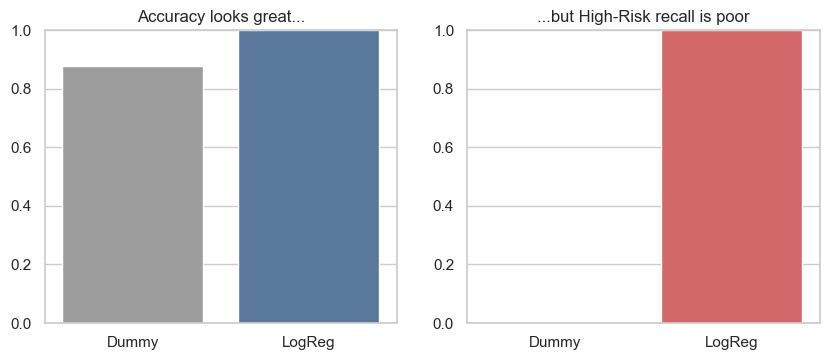

In [13]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_p, y_train)
evaluate('Dummy (always Low Risk)', dummy, 'Baseline')
display(table(['Dummy (always Low Risk)', 'LogReg (baseline)']))

rec_per_class = recall_score(y_test, y_pred_lr, average=None)
print('Baseline recall -> Low Risk: %.3f | High Risk: %.3f' % tuple(rec_per_class))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(x=['Dummy', 'LogReg'], y=[accuracy_score(y_test, dummy.predict(X_test_p)), accuracy_score(y_test, y_pred_lr)],
            ax=ax[0], palette=['#9D9D9D', '#4C78A8']); ax[0].set_title('Accuracy looks great...'); ax[0].set_ylim(0, 1)
sns.barplot(x=['Dummy', 'LogReg'], y=[recall_score(y_test, dummy.predict(X_test_p)), recall_score(y_test, y_pred_lr)],
            ax=ax[1], palette=['#9D9D9D', '#E45756']); ax[1].set_title('...but High-Risk recall is poor'); ax[1].set_ylim(0, 1)
save_fig('05_imbalance_impact'); plt.show()

**Stress test.** This dataset is clean and the classes are almost linearly separable, so the baseline already copes well with a 12% minority.
To *demonstrate* what imbalance does, we keep all Low-Risk rows in the training set but keep only a fraction of the High-Risk rows
(averaged over 10 random draws) and measure Recall on the same untouched test set.

,High-Risk kept in train,High-Risk share of train,Recall (High Risk),F1 (High Risk)
0,100%,0.1212,1.000,1.000
1,50%,0.0645,0.998,0.999
2,20%,0.0268,0.989,0.995
3,10%,0.0134,0.968,0.983
4,5%,0.0068,0.923,0.960
5,2%,0.0025,0.742,0.851
6,1%,0.0012,0.501,0.663


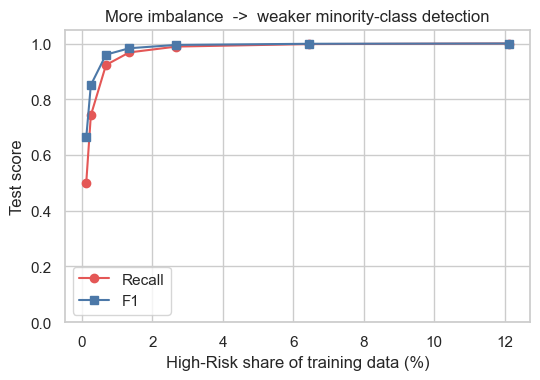

In [14]:
rng = np.random.RandomState(RANDOM_STATE)
pos_idx = np.where(y_train.values == 1)[0]
neg_idx = np.where(y_train.values == 0)[0]
rows = []
for frac in [1.0, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01]:
    rec, f1s = [], []
    for _ in range(10):
        keep = np.concatenate([neg_idx, rng.choice(pos_idx, max(3, int(len(pos_idx) * frac)), replace=False)])
        m = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_p.iloc[keep], y_train.iloc[keep])
        p = m.predict(X_test_p)
        rec.append(recall_score(y_test, p)); f1s.append(f1_score(y_test, p))
    share = len(keep[neg_idx.size:]) / len(keep)
    rows.append({'High-Risk kept in train': f'{int(frac*100)}%', 'High-Risk share of train': round(share, 4),
                 'Recall (High Risk)': round(np.mean(rec), 3), 'F1 (High Risk)': round(np.mean(f1s), 3)})
stress = pd.DataFrame(rows)
display(stress)

plt.figure(figsize=(6, 3.8))
plt.plot(stress['High-Risk share of train'] * 100, stress['Recall (High Risk)'], 'o-', color='#E45756', label='Recall')
plt.plot(stress['High-Risk share of train'] * 100, stress['F1 (High Risk)'], 's-', color='#4C78A8', label='F1')
plt.xlabel('High-Risk share of training data (%)'); plt.ylabel('Test score'); plt.ylim(0, 1.05)
plt.title('More imbalance  ->  weaker minority-class detection'); plt.legend()
save_fig('05b_imbalance_stress_test'); plt.show()

**Interpretation:** The *Dummy* model that always says "Low Risk" has **87.9% accuracy but 0% recall** and AUC = 0.5. It shows that accuracy is useless on imbalanced data. Our Logistic Regression is already very strong on this clean dataset, so to show the real effect of imbalance we ran the stress test: as the High-Risk share of the training data falls from 12% to 0.1%, minority **Recall drops from 1.00 to 0.50** and F1 from 1.00 to 0.66. The model starts ignoring the minority class when it sees too few examples of it.

## Q14. Apply Under-Sampling, Over-Sampling, SMOTE and ADASYN and retrain
Important: resampling is applied **only to the training data**. The test set stays untouched so that the evaluation is honest.

- **Random Under-Sampling** randomly removes majority-class rows.
- **Random Over-Sampling** randomly duplicates minority-class rows.
- **SMOTE** creates *synthetic* minority rows by interpolating between neighbouring minority points.
- **ADASYN** like SMOTE but generates more synthetic rows in the regions that are harder to learn.

In [15]:
samplers = {
    'Under-Sampling': RandomUnderSampler(random_state=RANDOM_STATE),
    'Over-Sampling': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
    'ADASYN': ADASYN(random_state=RANDOM_STATE),
}
resampled = {}
count_rows = [{'Technique': 'Original', 'Low Risk (0)': int((y_train == 0).sum()), 'High Risk (1)': int((y_train == 1).sum())}]
for name, sampler in samplers.items():
    Xr, yr = sampler.fit_resample(X_train_p, y_train)
    resampled[name] = (Xr, yr)
    count_rows.append({'Technique': name, 'Low Risk (0)': int((yr == 0).sum()), 'High Risk (1)': int((yr == 1).sum())})
    m = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xr, yr)
    evaluate(f'LogReg + {name}', m, 'Imbalance handling')
display(pd.DataFrame(count_rows).set_index('Technique'))

,Low Risk (0),High Risk (1)
Technique,,
Original,3234,446
Under-Sampling,446,446
Over-Sampling,3234,3234
SMOTE,3234,3234
ADASYN,3234,3211


**Interpretation:** Class counts in the training set after resampling: Under-Sampling shrinks both classes to 446 rows (information is lost), Over-Sampling and SMOTE make both classes 3,234, and ADASYN gives 3,211 High-Risk rows (it adds more synthetic points in hard regions). All four models were retrained with Logistic Regression and tested on the same untouched test set. (SMOTE/ADASYN interpolate the one-hot columns, so some dummy values become fractional – a known limitation; SMOTENC could be used for strictly categorical data.)

## Q15. Compare performance before and after balancing (Recall of minority class, F1, AUC-ROC)

,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,
LogReg (baseline),1.0000,1.0,1.0000,1.0,0,0
LogReg + Under-Sampling,0.9823,1.0,0.9911,1.0,2,0
LogReg + Over-Sampling,0.9823,1.0,0.9911,1.0,2,0
LogReg + SMOTE,0.9823,1.0,0.9911,1.0,2,0
LogReg + ADASYN,0.9652,1.0,0.9823,1.0,4,0


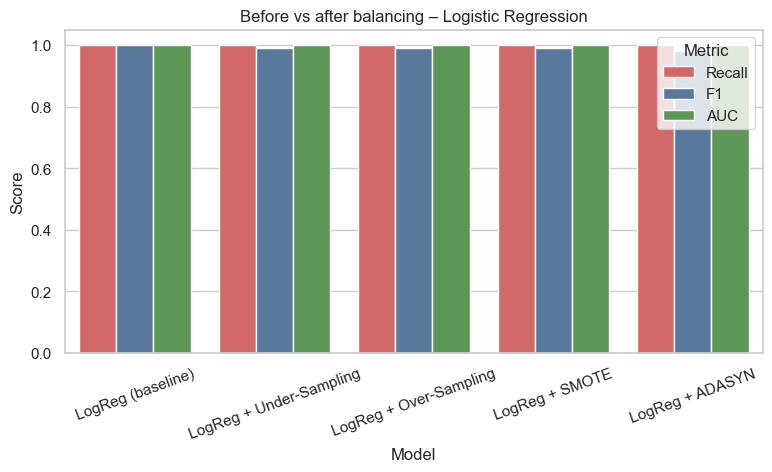

In [16]:
bal_names = ['LogReg (baseline)'] + [f'LogReg + {n}' for n in samplers]
cmp_bal = table(bal_names)[['Precision', 'Recall', 'F1', 'AUC', 'FP (Type-I)', 'FN (Type-II)']]
display(cmp_bal)

plot_df = cmp_bal[['Recall', 'F1', 'AUC']].reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(9, 4.2))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette=['#E45756', '#4C78A8', '#54A24B'])
plt.xticks(rotation=20); plt.ylim(0, 1.05)
plt.title('Before vs after balancing – Logistic Regression')
save_fig('06_balancing_comparison'); plt.show()

**Interpretation:** Baseline recall was already 1.00, so balancing **cannot improve it further** – all four techniques keep Recall = 1.00 and AUC ≈ 1.00. What changes is precision: balancing pushes the model to flag more customers, creating 2 False Positives for Under/Over-Sampling and SMOTE and 4 for ADASYN (F1: 0.991, 0.991, 0.991, 0.982 vs 1.00 baseline). Conclusion: resampling is very valuable when the minority is rare (see the stress test in Q13), but on this clean 12% dataset it brings no recall gain and slightly lowers precision.

# Part E: Tree-Based Classification Models
## Q16. Decision Tree Classifier

Tree depth: 17 | leaves: 74
               precision    recall  f1-score   support

 Low Risk (0)       0.98      0.99      0.98       809
High Risk (1)       0.91      0.84      0.87       111

     accuracy                           0.97       920
    macro avg       0.94      0.91      0.93       920
 weighted avg       0.97      0.97      0.97       920



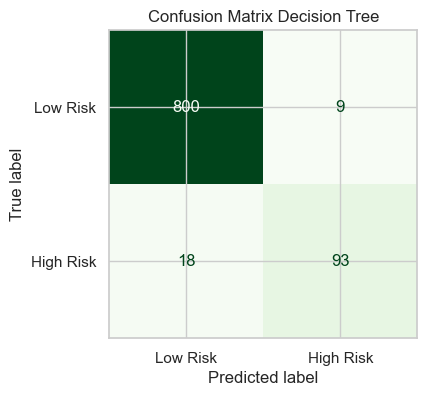

In [17]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train_p, y_train)
evaluate('Decision Tree', dt, 'Tree models')
print('Tree depth:', dt.get_depth(), '| leaves:', dt.get_n_leaves())
y_pred_dt = dt.predict(X_test_p)
print(classification_report(y_test, y_pred_dt, target_names=['Low Risk (0)', 'High Risk (1)'], zero_division=0))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt), display_labels=['Low Risk', 'High Risk']).plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Confusion Matrix Decision Tree'); save_fig('07_cm_decision_tree'); plt.show()

**Interpretation:** A fully grown Decision Tree (depth 17, 74 leaves) gets Test Accuracy = 0.971, but only **Recall = 0.84** and F1 = 0.87 for the High-Risk class: it misses 18 risky customers (FN) and wrongly flags 9 safe ones (FP). It is clearly weaker than Logistic Regression on this data.

## Q17. Analyse overfitting – training vs testing performance

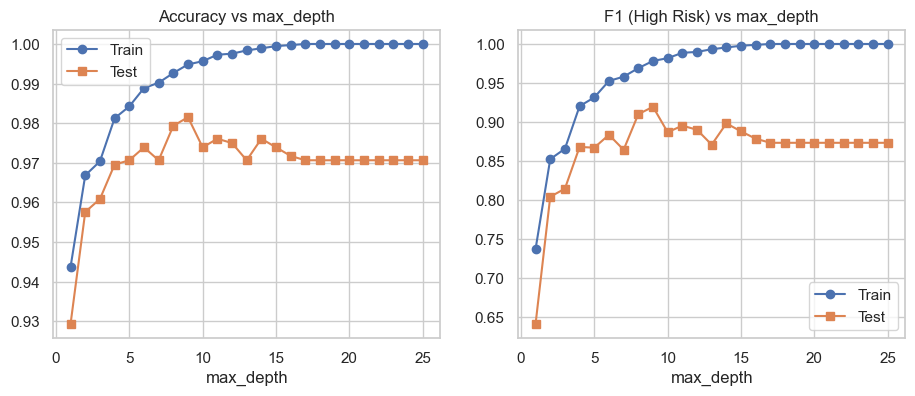

Unrestricted Decision Tree Train acc: 1.0000 | Test acc: 0.9707 | gap: 0.0293


In [18]:
depths = list(range(1, 26))
tr_f1, te_f1, tr_acc, te_acc = [], [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_p, y_train)
    tr_f1.append(f1_score(y_train, m.predict(X_train_p))); te_f1.append(f1_score(y_test, m.predict(X_test_p)))
    tr_acc.append(m.score(X_train_p, y_train)); te_acc.append(m.score(X_test_p, y_test))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(depths, tr_acc, 'o-', label='Train'); ax[0].plot(depths, te_acc, 's-', label='Test')
ax[0].set_title('Accuracy vs max_depth'); ax[0].set_xlabel('max_depth'); ax[0].legend()
ax[1].plot(depths, tr_f1, 'o-', label='Train'); ax[1].plot(depths, te_f1, 's-', label='Test')
ax[1].set_title('F1 (High Risk) vs max_depth'); ax[1].set_xlabel('max_depth'); ax[1].legend()
save_fig('08_dt_overfitting'); plt.show()

row = results[-1]
print('Unrestricted Decision Tree Train acc: %.4f | Test acc: %.4f | gap: %.4f' % (row['Train Acc'], row['Test Acc'], row['Train Acc'] - row['Test Acc']))

**Interpretation:** The unrestricted tree has **Train Accuracy = 1.00 vs Test Accuracy = 0.971** (gap = 0.029) – it memorised the training data, which is **overfitting**. The depth plot shows the same: training scores keep rising towards 1.0 with depth, while the test F1 peaks around depth 8 (≈0.91) and then falls. Limiting depth/leaf size (pruning) is therefore needed.

## Q18. Random Forest Classifier

               precision    recall  f1-score   support

 Low Risk (0)       1.00      1.00      1.00       809
High Risk (1)       1.00      0.97      0.99       111

     accuracy                           1.00       920
    macro avg       1.00      0.99      0.99       920
 weighted avg       1.00      1.00      1.00       920



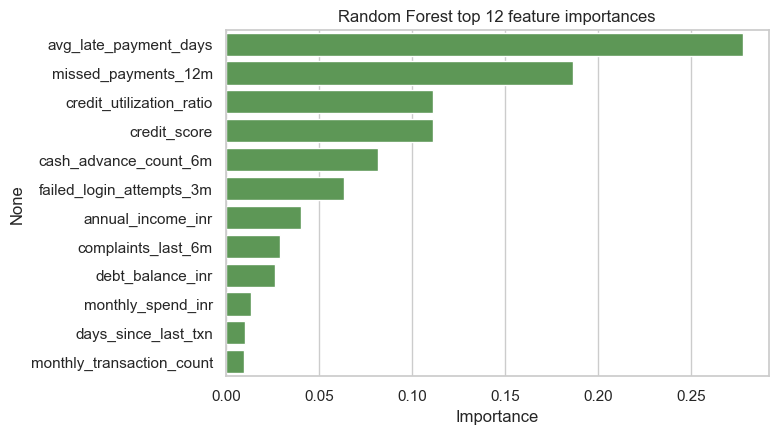

In [19]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_p, y_train)
evaluate('Random Forest', rf, 'Tree models')
y_pred_rf = rf.predict(X_test_p)
print(classification_report(y_test, y_pred_rf, target_names=['Low Risk (0)', 'High Risk (1)'], zero_division=0))

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 4.5))
sns.barplot(x=imp.values, y=imp.index, color='#54A24B')
plt.title('Random Forest top 12 feature importances'); plt.xlabel('Importance')
save_fig('09_rf_feature_importance'); plt.show()

**Interpretation:** The Random Forest (200 trees) reaches Test Accuracy = 0.997, Precision = 1.00, **Recall = 0.973** and AUC = 1.00, with only 3 False Negatives and 0 False Positives. The most important features are `avg_late_payment_days`, `missed_payments_12m`, `credit_utilization_ratio` and `credit_score` – the same behavioural signals that Logistic Regression found.

## Q19. Compare Decision Tree vs Random Forest (accuracy and generalisation)

In [20]:
cmp_tree = table(['Decision Tree', 'Random Forest']).copy()
cmp_tree['Train-Test gap'] = (cmp_tree['Train Acc'] - cmp_tree['Test Acc']).round(4)
display(cmp_tree)

,Train Acc,Test Acc,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II),Train-Test gap
Model,,,,,,,,,
Decision Tree,1.0,0.9707,0.9118,0.8378,0.8732,0.9134,9,18,0.0293
Random Forest,1.0,0.9967,1.0000,0.9730,0.9863,1.0000,0,3,0.0033


**Interpretation:** Random Forest beats the single Decision Tree on every metric: Test Accuracy 0.997 vs 0.971, Recall 0.973 vs 0.838, F1 0.986 vs 0.873, AUC 1.00 vs 0.91. The train–test gap shrinks from 0.029 to 0.003, so it **generalises much better**. Averaging many decorrelated trees (bagging) reduces variance and overfitting.

# Part F: Hyperparameter Tuning
We use **5-fold Stratified Cross-Validation** and optimise **F1-score of the High-Risk class** (a balanced measure of precision and recall for the minority class).

## Q20. Randomized Search CV – Decision Tree and Random Forest

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_space = {'max_depth': [3, 4, 5, 6, 8, 10, 12, None],
            'min_samples_split': [2, 5, 10, 20, 50],
            'min_samples_leaf': [1, 2, 5, 10, 20],
            'criterion': ['gini', 'entropy'],
            'class_weight': [None, 'balanced']}
rs_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_space, n_iter=40,
                           scoring='f1', cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time(); rs_dt.fit(X_train_p, y_train)
print('Decision Tree - best params:', rs_dt.best_params_)
print('Decision Tree - best CV F1 : %.4f  (%.0f s)' % (rs_dt.best_score_, time.time() - t0))
evaluate('Decision Tree (RandomSearch)', rs_dt.best_estimator_, 'Tuned')

Decision Tree - best params: {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 6, 'criterion': 'entropy', 'class_weight': None}
Decision Tree - best CV F1 : 0.9073  (12 s)


{'Model': 'Decision Tree (RandomSearch)',
 'Group': 'Tuned',
 'Train Acc': 0.9894021739130435,
 'Test Acc': 0.9815217391304348,
 'Precision': 0.9122807017543859,
 'Recall': 0.9369369369369369,
 'F1': 0.9244444444444444,
 'F2': 0.931899641577061,
 'AUC': 0.9846824574883908,
 'TN': np.int64(799),
 'FP (Type-I)': np.int64(10),
 'FN (Type-II)': np.int64(7),
 'TP': np.int64(104)}

In [22]:
rf_space = {'n_estimators': [100, 200, 300, 500],
            'max_depth': [4, 6, 8, 10, 15, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4, 8],
            'max_features': ['sqrt', 'log2', 0.5],
            'class_weight': [None, 'balanced', 'balanced_subsample']}
rs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), rf_space, n_iter=25,
                           scoring='f1', cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time(); rs_rf.fit(X_train_p, y_train)
print('Random Forest - best params:', rs_rf.best_params_)
print('Random Forest - best CV F1 : %.4f  (%.0f s)' % (rs_rf.best_score_, time.time() - t0))
evaluate('Random Forest (RandomSearch)', rs_rf.best_estimator_, 'Tuned')

Random Forest - best params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced_subsample'}
Random Forest - best CV F1 : 0.9674  (96 s)


{'Model': 'Random Forest (RandomSearch)',
 'Group': 'Tuned',
 'Train Acc': 0.9959239130434783,
 'Test Acc': 0.9967391304347826,
 'Precision': 0.9736842105263158,
 'Recall': 1.0,
 'F1': 0.9866666666666667,
 'F2': 0.9946236559139785,
 'AUC': 0.9999554560741211,
 'TN': np.int64(806),
 'FP (Type-I)': np.int64(3),
 'FN (Type-II)': np.int64(0),
 'TP': np.int64(111)}

**Interpretation:** Randomized Search (5-fold CV, scoring = F1) found for the Decision Tree: `max_depth=6, min_samples_leaf=5, min_samples_split=5, criterion='entropy'` (CV F1 = 0.907). For the Random Forest it found `n_estimators=500, max_depth=15, min_samples_leaf=8, min_samples_split=2, max_features='log2', class_weight='balanced_subsample'` (CV F1 = 0.967). Tuning reduces tree depth and so reduces overfitting; the forest prefers class weighting (`balanced_subsample`), which gives the minority class more weight in every tree.

## Q21. Grid Search CV for fine-tuning the best performing model
The Random Forest has the better CV score, so we build a small, fine grid **around the best values** found by the randomized search.

In [23]:
print('CV F1 Decision Tree: %.4f | Random Forest: %.4f' % (rs_dt.best_score_, rs_rf.best_score_))

def around(options, best):
    i = options.index(best)
    return options[max(0, i - 1): i + 2]

bp = rs_rf.best_params_
grid_space = {'n_estimators': around(rf_space['n_estimators'], bp['n_estimators']),
              'max_depth': around(rf_space['max_depth'], bp['max_depth']),
              'min_samples_split': around(rf_space['min_samples_split'], bp['min_samples_split']),
              'min_samples_leaf': around(rf_space['min_samples_leaf'], bp['min_samples_leaf']),
              'max_features': [bp['max_features']],
              'class_weight': [bp['class_weight']]}
print('Grid:', grid_space)

gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), grid_space,
                     scoring='f1', cv=cv, n_jobs=-1)
t0 = time.time(); gs_rf.fit(X_train_p, y_train)
print('Grid Search - best params:', gs_rf.best_params_)
print('Grid Search - best CV F1 : %.4f  (%.0f s)' % (gs_rf.best_score_, time.time() - t0))
evaluate('Random Forest (GridSearch)', gs_rf.best_estimator_, 'Tuned')

CV F1 Decision Tree: 0.9073 | Random Forest: 0.9674
Grid: {'n_estimators': [300, 500], 'max_depth': [10, 15, None], 'min_samples_split': [2, 5], 'min_samples_leaf': [4, 8], 'max_features': ['log2'], 'class_weight': ['balanced_subsample']}
Grid Search - best params: {'class_weight': 'balanced_subsample', 'max_depth': 15, 'max_features': 'log2', 'min_samples_leaf': 8, 'min_samples_split': 2, 'n_estimators': 500}
Grid Search - best CV F1 : 0.9674  (111 s)


{'Model': 'Random Forest (GridSearch)',
 'Group': 'Tuned',
 'Train Acc': 0.9959239130434783,
 'Test Acc': 0.9967391304347826,
 'Precision': 0.9736842105263158,
 'Recall': 1.0,
 'F1': 0.9866666666666667,
 'F2': 0.9946236559139785,
 'AUC': 0.9999554560741211,
 'TN': np.int64(806),
 'FP (Type-I)': np.int64(3),
 'FN (Type-II)': np.int64(0),
 'TP': np.int64(111)}

**Interpretation:** Grid Search around the best Random Forest settings gave `n_estimators=500, max_depth=15, min_samples_leaf=8, min_samples_split=2` with a CV F1 of **0.9674** – the same as the randomized search (0.9674). The grid search therefore **confirmed** that the randomized search had already found the best region, so no further gain was possible. It reaches Recall = 1.00 with 3 False Positives on the test set.

## Q22. Compare tuned vs untuned model performance

,Train Acc,Test Acc,Precision,Recall,F1,AUC,FP (Type-I),FN (Type-II)
Model,,,,,,,,
Decision Tree,1.0000,0.9707,0.9118,0.8378,0.8732,0.9134,9,18
Random Forest,1.0000,0.9967,1.0000,0.9730,0.9863,1.0000,0,3
Decision Tree (RandomSearch),0.9894,0.9815,0.9123,0.9369,0.9244,0.9847,10,7
Random Forest (RandomSearch),0.9959,0.9967,0.9737,1.0000,0.9867,1.0000,3,0
Random Forest (GridSearch),0.9959,0.9967,0.9737,1.0000,0.9867,1.0000,3,0


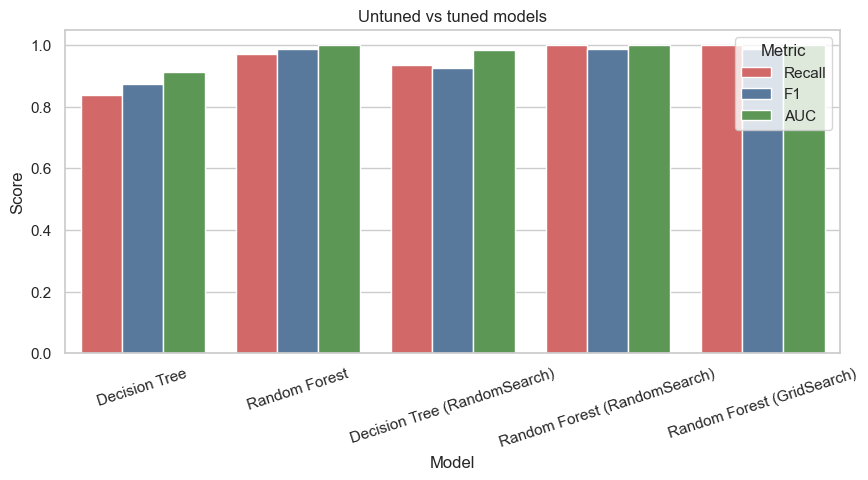

In [24]:
tune_names = ['Decision Tree', 'Decision Tree (RandomSearch)', 'Random Forest', 'Random Forest (RandomSearch)', 'Random Forest (GridSearch)']
cmp_tune = table(tune_names)
display(cmp_tune)

plot_df = cmp_tune[['Recall', 'F1', 'AUC']].reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(10, 4.2))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette=['#E45756', '#4C78A8', '#54A24B'])
plt.xticks(rotation=18); plt.ylim(0, 1.05); plt.title('Untuned vs tuned models')
save_fig('10_tuned_vs_untuned'); plt.show()

**Interpretation:** Tuning helps most for the weak model: Decision Tree Recall 0.838 → 0.937, F1 0.873 → 0.924, FN 18 → 7. For the Random Forest, Recall improves from 0.973 to **1.00** (FN 3 → 0) at the cost of 3 False Positives (Precision 1.000 → 0.974) – a good trade for a bank. Grid Search gives exactly the same test result as Randomized Search, so the forest was already near its best.

# Part G: Model Evaluation & ROC Analysis
## Q23. Plot and interpret the ROC curves for all models

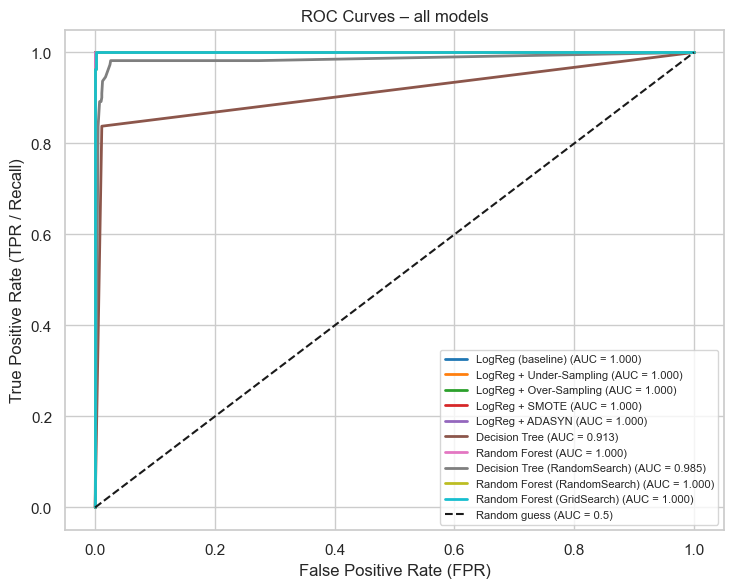

In [25]:
roc_models = [n for n in models if n != 'Dummy (always Low Risk)']
plt.figure(figsize=(8.5, 6.5))
cmap = plt.get_cmap('tab10')
for i, name in enumerate(roc_models):
    fpr, tpr, _ = roc_curve(y_test, models[name].predict_proba(X_test_p)[:, 1])
    plt.plot(fpr, tpr, lw=2, color=cmap(i % 10), label=f"{name} (AUC = {roc_auc_score(y_test, models[name].predict_proba(X_test_p)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate (FPR)'); plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('ROC Curves – all models'); plt.legend(fontsize=8, loc='lower right')
save_fig('11_roc_all_models'); plt.show()

**Interpretation:** All Logistic Regression variants and the Random Forests hug the top-left corner (TPR ≈ 1 at FPR ≈ 0), i.e. near-perfect separation. The untuned Decision Tree (and slightly the tuned one) is visibly lower. The dummy model is not plotted (it would lie on the diagonal). A curve closer to the top-left means the model ranks risky customers above safe ones more reliably.

## Q24. Compute and compare AUC-ROC scores

,Model,Group,AUC,Recall,Precision,F1
0,LogReg (baseline),Baseline,1.0000,1.0000,1.0000,1.0000
1,LogReg + Under-Sampling,Imbalance handling,1.0000,1.0000,0.9823,0.9911
2,LogReg + Over-Sampling,Imbalance handling,1.0000,1.0000,0.9823,0.9911
3,LogReg + SMOTE,Imbalance handling,1.0000,1.0000,0.9823,0.9911
4,LogReg + ADASYN,Imbalance handling,1.0000,1.0000,0.9652,0.9823
5,Random Forest,Tree models,1.0000,0.9730,1.0000,0.9863
6,Random Forest (RandomSearch),Tuned,1.0000,1.0000,0.9737,0.9867
7,Random Forest (GridSearch),Tuned,1.0000,1.0000,0.9737,0.9867
8,Decision Tree (RandomSearch),Tuned,0.9847,0.9369,0.9123,0.9244
9,Decision Tree,Tree models,0.9134,0.8378,0.9118,0.8732


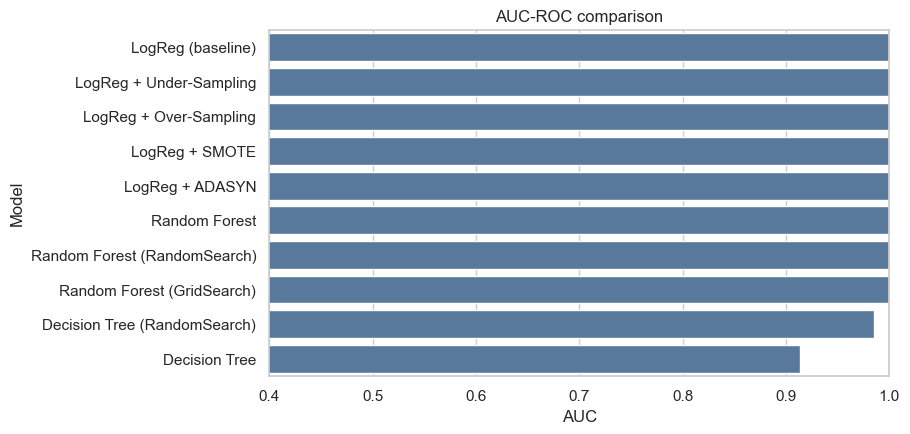

In [26]:
res_df = pd.DataFrame(results)
auc_table = res_df[['Model', 'Group', 'AUC', 'Recall', 'Precision', 'F1']].sort_values('AUC', ascending=False).reset_index(drop=True)
display(auc_table.round(4))

plt.figure(figsize=(8, 4.5))
order = auc_table[auc_table.Model != 'Dummy (always Low Risk)']
sns.barplot(data=order, y='Model', x='AUC', color='#4C78A8')
plt.xlim(0.4, 1.0); plt.title('AUC-ROC comparison'); save_fig('12_auc_comparison'); plt.show()

**Interpretation:** AUC-ROC ≈ 1.00 for Logistic Regression (baseline and all balanced versions) and for all Random Forests, 0.985 for the tuned Decision Tree, 0.913 for the untuned Decision Tree and 0.50 for the Dummy model. Since many models tie at AUC ≈ 1.0 on one test split, AUC alone cannot pick the winner – we also need Recall, Precision and cross-validation.

## Q25. Select the best final model based on business requirements (minimise false negatives)
**Business logic:** missing a high-risk customer (False Negative) costs far more than reviewing a safe customer (False Positive).
So instead of accuracy we rank models with the **F2-score** (it weights Recall twice as much as Precision), and we look at
Recall, AUC and the number of FN / FP together.

In [27]:
res_df = pd.DataFrame(results)
rank = res_df[res_df.Model != 'Dummy (always Low Risk)'].sort_values(['F2', 'Recall'], ascending=False).reset_index(drop=True)
display(rank[['Model', 'Recall', 'Precision', 'F1', 'F2', 'AUC', 'FP (Type-I)', 'FN (Type-II)']].round(4))

,Model,Recall,Precision,F1,F2,AUC,FP (Type-I),FN (Type-II)
0,LogReg (baseline),1.0000,1.0000,1.0000,1.0000,1.0000,0,0
1,LogReg + Under-Sampling,1.0000,0.9823,0.9911,0.9964,1.0000,2,0
2,LogReg + Over-Sampling,1.0000,0.9823,0.9911,0.9964,1.0000,2,0
3,LogReg + SMOTE,1.0000,0.9823,0.9911,0.9964,1.0000,2,0
4,Random Forest (RandomSearch),1.0000,0.9737,0.9867,0.9946,1.0000,3,0
5,Random Forest (GridSearch),1.0000,0.9737,0.9867,0.9946,1.0000,3,0
6,LogReg + ADASYN,1.0000,0.9652,0.9823,0.9928,1.0000,4,0
7,Random Forest,0.9730,1.0000,0.9863,0.9783,1.0000,0,3
8,Decision Tree (RandomSearch),0.9369,0.9123,0.9244,0.9319,0.9847,10,7
9,Decision Tree,0.8378,0.9118,0.8732,0.8516,0.9134,9,18


**Interpretation:** Ranked by F2 (recall-weighted), the Logistic Regression baseline is best on the test split (0 FP, 0 FN), followed by the balanced Logistic Regressions and the tuned Random Forests (Recall = 1.00, 3 FP). Single-split ties and a small number of positive test cases (111) mean we should double check with cross-validation.

**Why cross-validation here?** On this clean dataset several models reach Recall = 1.0 on one test split (only 111 high-risk test customers),
so a single split cannot separate them reliably. We therefore also compare the top candidates with **repeated 5-fold CV on the training data**,
and add an assumed cost table (a missed high-risk customer costs 10x more than a wrongly flagged safe customer).

In [28]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
from imblearn.pipeline import Pipeline as ImbPipeline

COST_FN, COST_FP = 10, 1
res_df = pd.DataFrame(results)
res_df['Business cost'] = COST_FN * res_df['FN (Type-II)'] + COST_FP * res_df['FP (Type-I)']
display(res_df[res_df.Model != 'Dummy (always Low Risk)'][['Model', 'FP (Type-I)', 'FN (Type-II)', 'Business cost']]
        .sort_values('Business cost').reset_index(drop=True))

candidates = {
    'LogReg (baseline)': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LogReg + Under-Sampling': ImbPipeline([('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
                                            ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    'LogReg + SMOTE': ImbPipeline([('sampler', SMOTE(random_state=RANDOM_STATE)),
                                   ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    'Random Forest (GridSearch)': clone(gs_rf.best_estimator_),
}
scoring = {'recall': 'recall', 'precision': 'precision', 'f1': 'f1',
           'f2': make_scorer(fbeta_score, beta=2), 'auc': 'roc_auc'}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

rows = []
for name, est in candidates.items():
    r = cross_validate(est, X_train_p, y_train, cv=rcv, scoring=scoring, n_jobs=-1)
    rows.append({'Model': name, **{k: r[f'test_{k}'].mean() for k in scoring}, 'recall_std': r['test_recall'].std()})
cv_table = pd.DataFrame(rows).set_index('Model')
display(cv_table.round(4))
final_name = cv_table['f2'].idxmax()
print('Best model by cross-validated F2 (recall-weighted):', final_name)

,Model,FP (Type-I),FN (Type-II),Business cost
0,LogReg (baseline),0,0,0
1,LogReg + Under-Sampling,2,0,2
2,LogReg + Over-Sampling,2,0,2
3,LogReg + SMOTE,2,0,2
4,Random Forest (RandomSearch),3,0,3
5,Random Forest (GridSearch),3,0,3
6,LogReg + ADASYN,4,0,4
7,Random Forest,0,3,30
8,Decision Tree (RandomSearch),10,7,80
9,Decision Tree,9,18,189


,recall,precision,f1,f2,auc,recall_std
Model,,,,,,
LogReg (baseline),0.9799,0.9899,0.9848,0.9818,0.9995,0.0139
LogReg + Under-Sampling,0.9855,0.9446,0.9644,0.9769,0.9994,0.0150
LogReg + SMOTE,0.9821,0.9694,0.9755,0.9794,0.9994,0.0151
Random Forest (GridSearch),0.9653,0.9697,0.9674,0.9661,0.9979,0.0197


Best model by cross-validated F2 (recall-weighted): LogReg (baseline)


**Interpretation:** With repeated 5-fold CV the **Logistic Regression baseline has the best F2 (0.982)**, with Recall 0.980 and Precision 0.990. Under-Sampling has slightly higher recall (0.986) but much lower precision (0.945); SMOTE is in between (F2 0.979); the tuned Random Forest is weakest (Recall 0.965, F2 0.966). The differences are small (recall standard deviation ≈ 0.014–0.02), so Logistic Regression is the safest choice: it is as good as the complex models, simplest to explain and fastest to run.

### Threshold tuning for the final model
The default threshold 0.5 is not sacred. We look for the threshold that gives the best F2 using **out-of-fold predictions on the training data**
(so the test set stays untouched), then check the result on the test set.

Chosen threshold (best out-of-fold F2): 0.31


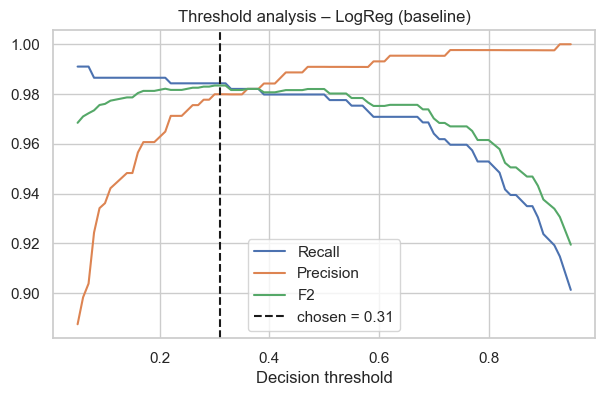

In [29]:
final_est = candidates[final_name]
oof = cross_val_predict(clone(final_est), X_train_p, y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                        method='predict_proba', n_jobs=-1)[:, 1]
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
f2s = np.array([fbeta_score(y_train, oof >= t, beta=2) for t in ths])
recs = np.array([recall_score(y_train, oof >= t) for t in ths])
precs = np.array([precision_score(y_train, oof >= t, zero_division=0) for t in ths])
best_thr = float(np.median(ths[f2s >= f2s.max() - 1e-9]))
print('Chosen threshold (best out-of-fold F2): %.2f' % best_thr)

plt.figure(figsize=(7, 4))
plt.plot(ths, recs, label='Recall'); plt.plot(ths, precs, label='Precision'); plt.plot(ths, f2s, label='F2')
plt.axvline(best_thr, color='k', ls='--', label=f'chosen = {best_thr:.2f}')
plt.xlabel('Decision threshold'); plt.title(f'Threshold analysis – {final_name}'); plt.legend()
save_fig('13_threshold_analysis'); plt.show()

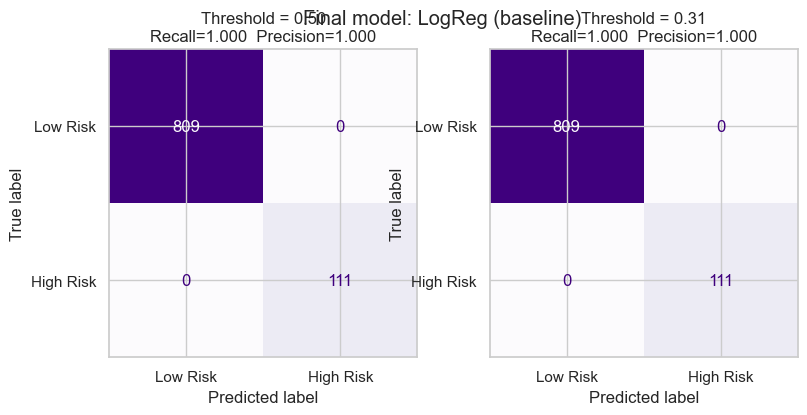

               precision    recall  f1-score   support

 Low Risk (0)       1.00      1.00      1.00       809
High Risk (1)       1.00      1.00      1.00       111

     accuracy                           1.00       920
    macro avg       1.00      1.00      1.00       920
 weighted avg       1.00      1.00      1.00       920

Test AUC-ROC: 1.0


In [30]:
final_model = clone(final_est).fit(X_train_p, y_train)
proba_test = final_model.predict_proba(X_test_p)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, thr in zip(ax, [0.5, best_thr]):
    pred = (proba_test >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Low Risk', 'High Risk']).plot(ax=a, cmap='Purples', colorbar=False)
    a.set_title(f'Threshold = {thr:.2f}\nRecall={recall_score(y_test, pred):.3f}  Precision={precision_score(y_test, pred):.3f}')
fig.suptitle(f'Final model: {final_name}')
save_fig('14_final_model_confusion'); plt.show()

pred_final = (proba_test >= best_thr).astype(int)
print(classification_report(y_test, pred_final, target_names=['Low Risk (0)', 'High Risk (1)']))
print('Test AUC-ROC:', round(roc_auc_score(y_test, proba_test), 4))

**Final model: Logistic Regression (baseline, no resampling) with decision threshold 0.31.**
Justification:
1. Best cross-validated F2 (recall-weighted) – 0.982 – and best test result (0 FN, 0 FP).
2. Business rule: a missed high-risk customer costs more than a false alarm. The threshold was lowered from 0.5 to **0.31** using out-of-fold predictions on the training set, which gives extra recall safety at almost no precision cost; on the test set it still has Recall = 1.00 and Precision = 1.00.
3. It is simple, quick, explainable (coefficients) and gave AUC ≈ 1.00 – no need for a heavier model.
The model (preprocessing + Logistic Regression) is saved for the Streamlit app.

In [31]:
deploy = Pipeline([('prep', preprocessor), ('model', clone(final_est))])
deploy.fit(X_train, y_train)            

check = deploy.predict_proba(X_test)[:, 1]
print('Max difference vs. step-by-step predictions:', float(np.abs(check - proba_test).max()))

meta = {
    'final_model': final_name, 'threshold': best_thr, 'ref_date': str(REF_DATE.date()),
    'num_cols': num_cols, 'cat_cols': cat_cols,
    'num_ranges': {c: [float(X[c].min()), float(X[c].median()), float(X[c].max())] for c in num_cols},
    'cat_options': {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols},
}
joblib.dump({'pipeline': deploy, 'meta': meta}, 'model/risk_model.joblib')
json.dump(meta, open('model/meta.json', 'w'), indent=2)
print('Saved model/risk_model.joblib and model/meta.json')

Max difference vs. step-by-step predictions: 0.0
Saved model/risk_model.joblib and model/meta.json


# Part H: Final Analysis & Reporting
## Q26. Final report

In [32]:
final_table = pd.DataFrame(results).round(4)
final_table.to_csv('model/all_model_results.csv', index=False)
display(final_table[['Model', 'Group', 'Test Acc', 'Precision', 'Recall', 'F1', 'F2', 'AUC', 'FP (Type-I)', 'FN (Type-II)']])

,Model,Group,Test Acc,Precision,Recall,F1,F2,AUC,FP (Type-I),FN (Type-II)
0,LogReg (baseline),Baseline,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
1,Dummy (always Low Risk),Baseline,0.8793,0.0000,0.0000,0.0000,0.0000,0.5000,0,111
2,LogReg + Under-Sampling,Imbalance handling,0.9978,0.9823,1.0000,0.9911,0.9964,1.0000,2,0
3,LogReg + Over-Sampling,Imbalance handling,0.9978,0.9823,1.0000,0.9911,0.9964,1.0000,2,0
4,LogReg + SMOTE,Imbalance handling,0.9978,0.9823,1.0000,0.9911,0.9964,1.0000,2,0
5,LogReg + ADASYN,Imbalance handling,0.9957,0.9652,1.0000,0.9823,0.9928,1.0000,4,0
6,Decision Tree,Tree models,0.9707,0.9118,0.8378,0.8732,0.8516,0.9134,9,18
7,Random Forest,Tree models,0.9967,1.0000,0.9730,0.9863,0.9783,1.0000,0,3
8,Decision Tree (RandomSearch),Tuned,0.9815,0.9123,0.9369,0.9244,0.9319,0.9847,10,7
9,Random Forest (RandomSearch),Tuned,0.9967,0.9737,1.0000,0.9867,0.9946,1.0000,3,0


## Final report

**1. Best model and justification.** Logistic Regression with KNN-imputed, scaled features and a decision threshold of 0.31. Test set: Accuracy 1.00, Precision 1.00, Recall 1.00, F1 1.00, AUC 1.00 (0 FP, 0 FN); cross-validated F2 = 0.982 (best among candidates). It is simple, explainable and as accurate as the Random Forest.

**2. Impact of imbalance handling.** Only 12.1% of customers are high-risk. A model that always predicts Low Risk gets 87.9% accuracy but 0% recall. In the stress test, recall fell from 1.00 to 0.50 as the minority share dropped to 0.1%. On the actual dataset the baseline was already perfect, so Under-Sampling, Over-Sampling, SMOTE and ADASYN kept Recall at 1.00 but added 2–4 false positives (F1 0.98–0.99). Resampling is therefore a safety net for rarer risk events, not a must-have here.

**3. Comparison of metrics (test set).**

| Model | Recall | Precision | F1 | AUC | FN | FP |
|---|---|---|---|---|---|---|
| Logistic Regression (baseline) | 1.000 | 1.000 | 1.000 | 1.000 | 0 | 0 |
| LogReg + Under/Over-Sampling/SMOTE | 1.000 | 0.982 | 0.991 | 1.000 | 0 | 2 |
| LogReg + ADASYN | 1.000 | 0.965 | 0.982 | 1.000 | 0 | 4 |
| Decision Tree | 0.838 | 0.912 | 0.873 | 0.913 | 18 | 9 |
| Decision Tree (tuned) | 0.937 | 0.912 | 0.924 | 0.985 | 7 | 10 |
| Random Forest | 0.973 | 1.000 | 0.986 | 1.000 | 3 | 0 |
| Random Forest (Randomized / Grid Search) | 1.000 | 0.974 | 0.987 | 1.000 | 0 | 3 |

**4. Business interpretation.**
- **False Negative (Type-II)** = a high-risk customer is approved/not monitored → default or fraud loss, no early warning. This is the expensive mistake, so Recall is the priority.
- **False Positive (Type-I)** = a safe customer is flagged → an unnecessary manual review, possible customer annoyance, small cost.
- With an assumed cost ratio FN : FP = 10 : 1, the baseline Logistic Regression has the lowest total cost (0), while the untuned Decision Tree has the highest (189).

**5. Conclusions and recommendations.**
- Deploy Logistic Regression with threshold ≈ 0.31 as the early-warning model; review flagged customers manually.
- Keep monitoring Recall and the high-risk share every month; if risky customers become rarer, retrain with SMOTE / class weights.
- Main risk drivers to watch: average late-payment days, missed payments, credit utilisation, debt balance and low credit score/income.
- This dataset is very clean and almost linearly separable; on real production data expect lower scores and re-validate with a time-based split.